# ET heatmaps with different variance metrics

In [1]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import etunc.config as cfg
from etunc.load.cmip import group_model_variants

In [2]:
PLUMBER_ROOT = Path("/glade/work/bbuchovecky/data/fluxnet_abramowitz")
L_V = 2.45e6
SEC_PER_YEAR = 86400 * 365.25
MIN_YEAR_THRESH = 3

In [20]:
met = {}
for f in sorted((PLUMBER_ROOT / "met").iterdir()):
    key = f.stem.split("_")[0]
    met[key] = xr.open_dataset(f)

flux = {}
for f in sorted((PLUMBER_ROOT / "flux").iterdir()):
    key = f.stem.split("_")[0]
    flux[key] = xr.open_dataset(f)

In [3]:
pool_all = {}
n_mem = {}
sigma_mem = {}
mu_mem = {}
cv_mem = {}

for fam in cfg.FAMILIES:
    pool_all[fam] = xr.open_dataset(cfg.PROC_ROOT / fam / "qbin" / f"{fam}.et.qbin_pooled_all.1deg.199501-201412.nc")
    et_mean = pool_all[fam].et.sel(stats="mean")
    n_mem[fam] =  pool_all[fam].et.sel(stats="count").sum(dim="member")
    if fam == "cmip":
        # One value per modeling group: average the members of each model, then the models of each group,
        # and take the mean and std across the group means
        model_mean = et_mean.groupby("source").mean()
        group_of = {sid: grp for grp, sids in group_model_variants(model_mean.source.values).items() for sid in sids}
        model_mean = model_mean.assign_coords(group=("source", [group_of[s] for s in model_mean.source.values]))
        group_mean = model_mean.groupby("group").mean()
        sigma_mem[fam] = group_mean.std(dim="group")
        mu_mem[fam] = group_mean.mean(dim="group")
    else:
        sigma_mem[fam] = et_mean.std(dim="member")
        mu_mem[fam] = et_mean.mean(dim="member")
    cv_mem[fam] = sigma_mem[fam] / mu_mem[fam]

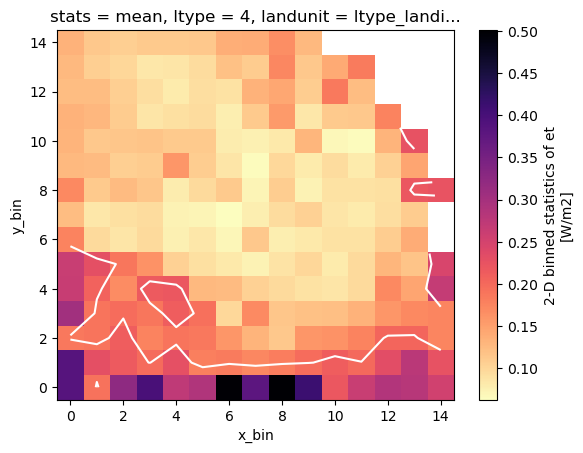

In [4]:
cv_mem["obs"].plot.pcolormesh(cmap="magma_r")
cv_mem["obs"].plot.contour(levels=[0.2], colors=["white"])

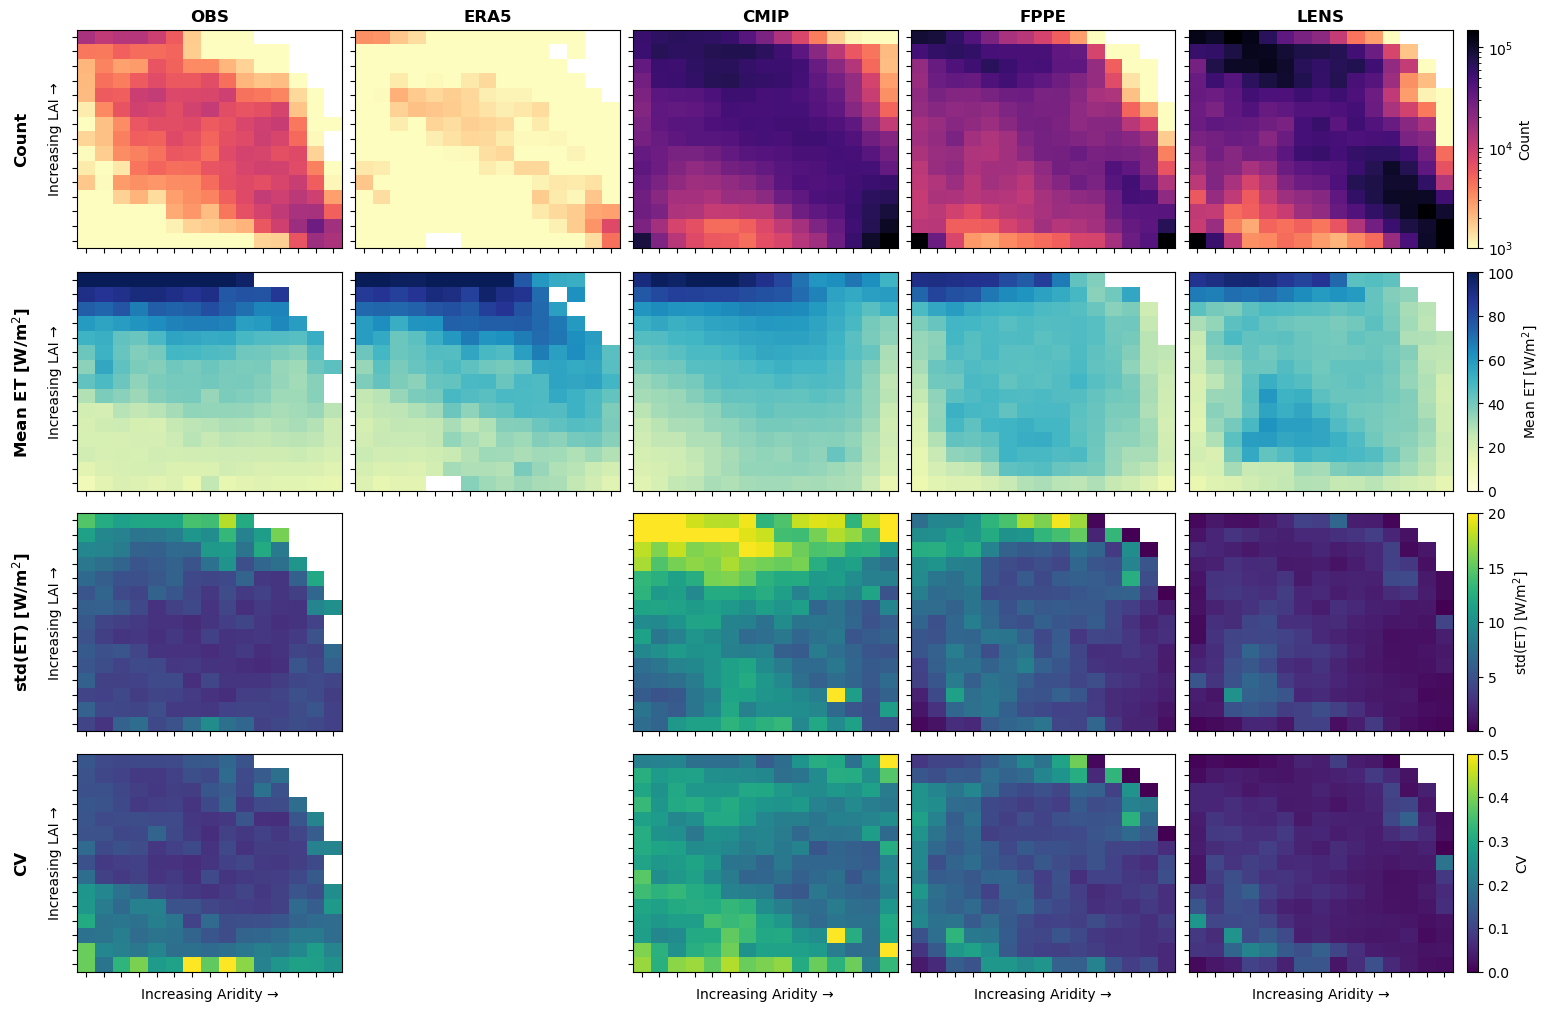

In [5]:
fig, axes = plt.subplots(4, len(cfg.FAMILIES), figsize=(15, 10), layout="constrained")
axs = axes.ravel()

vlims = [
    (1e3, 1.5e5), (0, 100), (0, 20), (0, 0.5),
]
cmaps = [
    "magma_r", "YlGnBu", "viridis", "viridis",
]

row_labels = ["Count", "Mean ET [W/m$^2$]", "std(ET) [W/m$^2$]", "CV"]
for i, (label, d) in enumerate(zip(row_labels, [n_mem, mu_mem, sigma_mem, cv_mem])):
    for j, fam in enumerate(cfg.FAMILIES):
        if i == 0:
            norm = mcolors.LogNorm()
        else:
            norm = None

        mappable = d[fam].plot(
            ax=axes[i, j],
            cmap=cmaps[i],
            vmin=vlims[i][0],
            vmax=vlims[i][1],
            add_labels=False,
            add_colorbar=False,
            norm=norm,
        )
        axes[i, j].set_xticks(np.arange(15))
        axes[i, j].set_yticks(np.arange(15))
        axes[i, j].set_xticklabels([])
        axes[i, j].set_yticklabels([])

        if i == 0:
            axes[i, j].set_title(fam.upper(), fontsize=12, fontweight="bold")
        if i == 3:
            axes[i, j].set_xlabel("Increasing Aridity →")
        if j == 0:
            axes[i, j].set_ylabel("Increasing LAI →")

    fig.colorbar(mappable, ax=axes[i, :], label=label, pad=0.01)

fig.canvas.draw()
for i, label in enumerate(row_labels):
    row_center = axes[i, 0].get_position().y0 + axes[i, 0].get_position().height / 2
    fig.text(-0.015, row_center, label, va="center", ha="center", fontsize=12, fontweight="bold", rotation=90)

axes[2, 1].remove()
axes[3, 1].remove()